# Hito 1 · Reposición de inventario

**EC2053C · Análisis de Datos II · Proyecto Capstone · Hito 1**
Universidad Católica de la Santísima Concepción · FACEA · Ingeniería en Información y Control de Gestión


---

Este cuaderno lleva el extracto de ventas semanales de la empresa Hogar Market (`HISTORICO VENTAS.xlsx`) a una
**matriz de diseño** y ajusta el primer modelo de regresión del proyecto.

### La decisión

> **Cada semana** el encargado de compras decide **cuántas unidades reponer** de cada uno de los
> **~580 productos activos**, y equivocarse cuesta ya que si pide de menos pierde el margen de la venta
> (quiebre de stock) y si pide de más inmoviliza dinero en la bodega y arriesga pérdidas.

### Las cuatro decisiones de diseño

| Decisión | Valor en este caso | Por qué |
|---|---|---|
| **Unidad de análisis** | Producto (código) | La reposición se decide producto por producto. |
| **Grano temporal** | Semanal | El extracto viene por semana y el pedido al proveedor es semanal. |
| **Ventana de observación** | 26 semanas antes de `t₀` | Medio año: cubre temporadas y deja ver productos lentos. |
| **Ventana de predicción** | 4 semanas después de `t₀` | Es el horizonte de un ciclo de compra (un mes). |

**Regla que ordena todo el cuaderno:** ninguna variable usa información posterior a `t₀`.

| Sección | Qué se hace |
|---|---|
| 0–2 | Configuración, carga del Excel y auditoría del extracto |
| 3–7 | `t₀`, población, variables candidatas, etiqueta y matriz |
| 8 | Auditoría de la matriz |
| 9 | Protocolo experimental: partición 70/30 y semilla |
| 10–12 | Línea base, VIF y regularización (Ridge vs Lasso) |
| 13–15 | Evaluación final en prueba, coeficientes y diagnóstico |
| 16 | Costo del error en pesos |

## 0. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 60)

SEED = 2053
rng = np.random.default_rng(SEED)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CARPETAS = ["data/raw", "data/interim", "data/processed", "notebooks", "src", "reports/figuras"]
for c in CARPETAS:
    (RAIZ / c).mkdir(parents=True, exist_ok=True)

gitignore = RAIZ / ".gitignore"
if not gitignore.exists():
    gitignore.write_text("data/raw/\ndata/interim/\n.ipynb_checkpoints/\n__pycache__/\n*.pyc\n.env\n",
                         encoding="utf-8")

TINTA, SECUND, TENUE, REJILLA, SUP = "#202126", "#595959", "#9CA3AF", "#E5E7EB", "#FFFFFF"
CAT = ["#C80F2E", "#1F6FB2", "#0F7A3E", "#B08800"]

mpl.rcParams.update({
    "figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "font.family": "sans-serif", "font.sans-serif": ["Calibri", "Carlito", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "axes.labelcolor": SECUND, "axes.labelsize": 9.5,
    "axes.edgecolor": REJILLA, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": SECUND, "ytick.color": SECUND, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

# --- parámetros de diseño (los únicos que se tocan al cambiar de caso) ---
T0_SEMANA  = 66        # t0 = cierre de la semana 66 (sábado 5 de septiembre de 2026)
VENT_OBS   = 26        # semanas hacia atrás
VENT_PRED  = 4         # semanas hacia adelante
INICIO_OBS = T0_SEMANA - VENT_OBS + 1      # semana 41
FIN_PRED   = T0_SEMANA + VENT_PRED         # semana 70

TEST_SIZE  = 0.30      # 70% entrenamiento · 30% prueba
CAT_COLS   = ["familia"]
CLAVES     = ["codigo", "semana_corte"]
OBJETIVO   = "unid_prox_4s"

ARCHIVO = RAIZ / "data/raw/HISTORICO VENTAS.xlsx"

print(f"Ventana de observación : semanas {INICIO_OBS} a {T0_SEMANA}")
print(f"Corte t0               : fin de la semana {T0_SEMANA}")
print(f"Ventana de predicción  : semanas {T0_SEMANA + 1} a {FIN_PRED}")
print(f"Partición              : {1 - TEST_SIZE:.0%} entrenamiento / {TEST_SIZE:.0%} prueba · semilla {SEED}")

Ventana de observación : semanas 41 a 66
Corte t0               : fin de la semana 66
Ventana de predicción  : semanas 67 a 70
Partición              : 70% entrenamiento / 30% prueba · semilla 2053


## 1. Carga del Excel

Se leerá el Excel directamente. 

In [2]:
ventas = pd.read_excel(ARCHIVO, sheet_name="VENTAS")
ventas["Fecha_Inicio_Semana"] = pd.to_datetime(ventas["Fecha_Inicio_Semana"])
ventas["Fecha_Fin_Semana"]    = pd.to_datetime(ventas["Fecha_Fin_Semana"])
ventas["Codigo"] = ventas["Codigo"].astype(str).str.strip()

print(f"Extracto: {ventas.shape[0]:,} filas × {ventas.shape[1]} columnas")
print(f"Semanas : {ventas['Semana_Nro'].min()} a {ventas['Semana_Nro'].max()}  "
      f"({ventas['Fecha_Inicio_Semana'].min():%Y-%m-%d} a {ventas['Fecha_Fin_Semana'].max():%Y-%m-%d})")
print(f"Productos distintos: {ventas['Codigo'].nunique():,}")
print(f"Familias           : {ventas['Familia_Producto'].nunique()}")
print()
print(ventas.dtypes.to_string())
print()
print(ventas.head(5).to_string())

Extracto: 17,163 filas × 12 columnas
Semanas : 1 a 71  (2025-06-01 a 2026-10-06)
Productos distintos: 689
Familias           : 8

Semana_Nro                        int64
Fecha_Inicio_Semana      datetime64[us]
Fecha_Fin_Semana         datetime64[us]
Ano_Semana                          str
Codigo                              str
Descripcion                         str
Familia_Producto                    str
Cantidad_Semanal                  int64
Precio_Venta_Unitario             int64
Precio_Costo_Unitario             int64
Total_Venta_Semanal               int64
Total_Costo_Semanal               int64

   Semana_Nro Fecha_Inicio_Semana Fecha_Fin_Semana Ano_Semana Codigo           Descripcion              Familia_Producto  Cantidad_Semanal  Precio_Venta_Unitario  Precio_Costo_Unitario  Total_Venta_Semanal  Total_Costo_Semanal
0           1          2025-06-01       2025-06-07   2025-W22      2  Bolsa Camiseta 35x40               Aseo y Limpieza                 1                    850 

## 2. Auditoría del extracto

Antes de construir nada se revisa la tabla. Cada hallazgo termina con una decisión escrita:
**la acepto y la corrijo**, o **la descarto y por qué**.

In [3]:
def auditar_extracto(df):
    filas = []
    # 1. duplicados exactos
    filas.append(("Filas duplicadas exactas", int(df.duplicated().sum())))
    # 2. mismo producto y semana en varias filas (distinto precio)
    filas.append(("Producto-semana repetido", int(df.duplicated(["Codigo", "Semana_Nro"]).sum())))
    # 3. faltantes
    filas.append(("Celdas vacías", int(df.isna().sum().sum())))
    # 4. cantidades imposibles
    filas.append(("Cantidad <= 0", int((df["Cantidad_Semanal"] <= 0).sum())))
    # 5. costo igual a cero (no existe producto gratis)
    filas.append(("Costo unitario = 0", int((df["Precio_Costo_Unitario"] == 0).sum())))
    # 6. venta bajo el costo
    filas.append(("Precio venta < costo", int((df["Precio_Venta_Unitario"] < df["Precio_Costo_Unitario"]).sum())))
    # 7. total que no cuadra con cantidad × precio
    filas.append(("Total ≠ cantidad × precio", int((df["Total_Venta_Semanal"] !=
                  df["Cantidad_Semanal"] * df["Precio_Venta_Unitario"]).sum())))
    # 8. códigos mal leídos (Excel convierte FALSO en booleano)
    filas.append(("Código = 'False'", int((df["Codigo"] == "False").sum())))
    # 9. semanas incompletas (menos de 7 días)
    dias = (df.groupby("Semana_Nro")["Fecha_Fin_Semana"].first()
            - df.groupby("Semana_Nro")["Fecha_Inicio_Semana"].first()).dt.days + 1
    filas.append(("Semanas con menos de 7 días", int((dias < 7).sum())))
    return pd.DataFrame(filas, columns=["comprobación", "casos"]), dias

audit, dias_semana = auditar_extracto(ventas)
print(audit.to_string(index=False))
print("\nSemana incompleta:", dias_semana[dias_semana < 7].to_dict(), "(semana: días)")

               comprobación  casos
   Filas duplicadas exactas     22
   Producto-semana repetido   3059
              Celdas vacías      0
              Cantidad <= 0      0
         Costo unitario = 0    787
       Precio venta < costo    477
  Total ≠ cantidad × precio      0
           Código = 'False'      5
Semanas con menos de 7 días      1

Semana incompleta: {71: 3} (semana: días)


In [4]:
DECISIONES_EXTRACTO = pd.DataFrame([
    {"alerta": "Producto-semana repetido",
     "decision": "corrijo",
     "justificacion": "Son ventas del mismo producto a distinto precio en la semana. Se SUMAN las "
                      "unidades por código y semana: para reponer importa el total vendido."},
    {"alerta": "Filas duplicadas exactas (22)",
     "decision": "descarto",
     "justificacion": "Son dos ventas iguales (misma cantidad y precio) dentro de la semana, no un "
                      "error de copia: el extracto es un resumen semanal por precio. Se conservan."},
    {"alerta": "Costo unitario = 0",
     "decision": "corrijo",
     "justificacion": "No existe producto gratis: el costo no se registró. Se trata como faltante "
                      "(NaN) al calcular el margen, y lo imputa el pipeline dentro del pliegue."},
    {"alerta": "Precio venta < costo",
     "decision": "descarto",
     "justificacion": "Son ofertas o liquidaciones, que sí ocurren en un minimarket. No afectan "
                      "las unidades vendidas, que es lo que se predice."},
    {"alerta": "Código = 'False'",
     "decision": "corrijo",
     "justificacion": "Excel convirtió un código a booleano y mezcla productos distintos "
                      "(cintillos y otro). Se eliminan esas 5 filas."},
    {"alerta": "Semana 71 incompleta (3 días)",
     "decision": "corrijo",
     "justificacion": "Si entrara en la etiqueta subestimaría la demanda. Por eso t0 = semana 66 y "
                      "la ventana de predicción termina en la semana 70."},
])
print(DECISIONES_EXTRACTO.to_string(index=False))
assert set(DECISIONES_EXTRACTO["decision"]) <= {"corrijo", "descarto"}

                       alerta decision                                                                                                                                           justificacion
     Producto-semana repetido  corrijo         Son ventas del mismo producto a distinto precio en la semana. Se SUMAN las unidades por código y semana: para reponer importa el total vendido.
Filas duplicadas exactas (22) descarto Son dos ventas iguales (misma cantidad y precio) dentro de la semana, no un error de copia: el extracto es un resumen semanal por precio. Se conservan.
           Costo unitario = 0  corrijo     No existe producto gratis: el costo no se registró. Se trata como faltante (NaN) al calcular el margen, y lo imputa el pipeline dentro del pliegue.
         Precio venta < costo descarto                               Son ofertas o liquidaciones, que sí ocurren en un minimarket. No afectan las unidades vendidas, que es lo que se predice.
             Código = 'False'  corrijo       

In [5]:
# Aplicar las correcciones
ventas = ventas.loc[ventas["Codigo"] != "False"].copy()
ventas["costo_unit"] = ventas["Precio_Costo_Unitario"].replace(0, np.nan)

# Llevar a una fila por producto y semana (suma de unidades y montos)
sem = (ventas.groupby(["Codigo", "Semana_Nro"])
       .agg(familia=("Familia_Producto", "first"),
            unidades=("Cantidad_Semanal", "sum"),
            venta=("Total_Venta_Semanal", "sum"),
            costo_unit=("costo_unit", "mean"))
       .reset_index()
       .rename(columns={"Codigo": "codigo", "Semana_Nro": "semana"}))
sem["precio_unit"] = sem["venta"] / sem["unidades"]

print(f"Tabla producto-semana: {sem.shape[0]:,} filas  ·  {sem['codigo'].nunique():,} productos")
sem.head()

Tabla producto-semana: 14,100 filas  ·  688 productos


,codigo,semana,familia,unidades,venta,costo_unit,precio_unit
0,.,19,"Papelería, Higiene y Pañales",1,20000,17890.0,20000.0
1,.,27,"Papelería, Higiene y Pañales",1,20000,17890.0,20000.0
2,.,34,"Papelería, Higiene y Pañales",1,20000,17890.0,20000.0
3,.,45,"Papelería, Higiene y Pañales",1,20000,17890.0,20000.0
4,1,2,Aseo y Limpieza,5,11000,1835.0,2200.0


## 3. Congelar `t₀`

Se parte el mundo en dos y no se vuelven a mezclar:

- **`obs`** — semanas 41 a 66. Es lo único que alimenta variables.
- **`fut`** — semanas 67 a 70. Sirve **únicamente** para construir la etiqueta.

In [6]:
obs = sem.loc[sem["semana"].between(INICIO_OBS, T0_SEMANA)].copy()
fut = sem.loc[sem["semana"].between(T0_SEMANA + 1, FIN_PRED)].copy()

print(f"Filas en observación : {len(obs):,}  (semanas {obs['semana'].min()} a {obs['semana'].max()})")
print(f"Filas en predicción  : {len(fut):,}  (semanas {fut['semana'].min()} a {fut['semana'].max()})")

assert obs["semana"].max() <= T0_SEMANA, "Hay semanas posteriores a t0 en la observación."
assert fut["semana"].min() > T0_SEMANA, "La etiqueta usa semanas anteriores a t0."
print("\nOK: no hay información posterior a t0 en el conjunto de observación.")

Filas en observación : 5,131  (semanas 41 a 66)
Filas en predicción  : 803  (semanas 67 a 70)

OK: no hay información posterior a t0 en el conjunto de observación.


## 4. Población

Entran a la matriz los productos **con al menos una venta en las 26 semanas de observación**: son los que
el encargado de compras tiene que decidir si repone. Un producto que no se vende hace medio año no
está en la conversación de compra.

In [7]:
poblacion = (obs[["codigo"]].drop_duplicates()
             .assign(semana_corte=T0_SEMANA)
             .sort_values("codigo").reset_index(drop=True))
print(f"Productos en el extracto      : {sem['codigo'].nunique():,}")
print(f"Productos con decisión en t0  : {len(poblacion):,}  "
      f"({len(poblacion)/sem['codigo'].nunique():.1%})")
print("Requisito de las bases: al menos 300 filas →", "CUMPLE" if len(poblacion) >= 300 else "NO CUMPLE")

Productos en el extracto      : 688
Productos con decisión en t0  : 585  (85.0%)
Requisito de las bases: al menos 300 filas → CUMPLE


## 5. Variables candidatas: 11

Se construyen **sólo con `obs`**. Para que las semanas sin venta cuenten como cero (y no como
"desconocido") primero se arma la grilla completa producto × semana.

| # | Variable | Qué mide |
|---|---|---|
| 1 | `unid_4s` | Unidades vendidas en las últimas 4 semanas |
| 2 | `unid_12s` | Unidades vendidas en las últimas 12 semanas |
| 3 | `unid_26s` | Unidades vendidas en las 26 semanas |
| 4 | `sd_unid_12s` | Variabilidad semanal (desv. estándar) en 12 semanas |
| 5 | `semanas_con_venta_12s` | Cuántas de las últimas 12 semanas tuvo venta |
| 6 | `recencia_semanas` | Semanas desde la última venta |
| 7 | `tendencia_4s_12s` | Ritmo de las últimas 4 semanas sobre el promedio de 12 |
| 8 | `precio_medio` | Precio de venta promedio por unidad |
| 9 | `margen_pct` | Margen bruto porcentual (precio − costo) / precio |
| 10 | `antiguedad_semanas` | Semanas desde la primera venta registrada |
| 11 | `familia` | Familia del producto (categórica) |

In [8]:
# grilla completa: cada producto de la población × cada semana de observación
grilla = pd.MultiIndex.from_product([poblacion["codigo"], range(INICIO_OBS, T0_SEMANA + 1)],
                                    names=["codigo", "semana"]).to_frame(index=False)
grilla = grilla.merge(obs[["codigo", "semana", "unidades"]], on=["codigo", "semana"], how="left")
grilla["unidades"] = grilla["unidades"].fillna(0)

def suma_ultimas(n):
    g = grilla.loc[grilla["semana"] > T0_SEMANA - n]
    return g.groupby("codigo")["unidades"].sum()

ult12 = grilla.loc[grilla["semana"] > T0_SEMANA - 12]

variables = pd.DataFrame({
    "unid_4s":  suma_ultimas(4),
    "unid_12s": suma_ultimas(12),
    "unid_26s": suma_ultimas(26),
    "sd_unid_12s": ult12.groupby("codigo")["unidades"].std(),
    "semanas_con_venta_12s": ult12.assign(v=ult12["unidades"] > 0).groupby("codigo")["v"].sum(),
}).reset_index()

ultima = obs.groupby("codigo")["semana"].max()
variables["recencia_semanas"] = variables["codigo"].map(T0_SEMANA - ultima)

prom_4s_en_12 = variables["unid_12s"] / 3          # promedio de un bloque de 4 semanas
variables["tendencia_4s_12s"] = np.where(prom_4s_en_12 > 0,
                                         variables["unid_4s"] / prom_4s_en_12, np.nan).round(3)

precios = obs.groupby("codigo").agg(venta=("venta", "sum"), unidades=("unidades", "sum"),
                                    costo_unit=("costo_unit", "mean"), familia=("familia", "first"))
precios["precio_medio"] = (precios["venta"] / precios["unidades"]).round(0)
precios["margen_pct"] = ((precios["precio_medio"] - precios["costo_unit"]) / precios["precio_medio"]).round(3)
variables = variables.merge(precios[["precio_medio", "margen_pct", "familia"]].reset_index(),
                            on="codigo", how="left")

# antigüedad: desde la primera venta registrada HASTA t0 (no contra hoy)
primera = sem.loc[sem["semana"] <= T0_SEMANA].groupby("codigo")["semana"].min()
variables["antiguedad_semanas"] = variables["codigo"].map(T0_SEMANA - primera + 1)

CANDIDATAS = ["unid_4s", "unid_12s", "unid_26s", "sd_unid_12s", "semanas_con_venta_12s",
              "recencia_semanas", "tendencia_4s_12s", "precio_medio", "margen_pct",
              "antiguedad_semanas", "familia"]
assert len(CANDIDATAS) <= 12, "Las bases piden no más de 12 variables candidatas."
print(f"Variables candidatas: {len(CANDIDATAS)}  (mínimo 8, máximo 12)\n")
print(variables[CANDIDATAS].describe().round(2).T.to_string())

Variables candidatas: 11  (mínimo 8, máximo 12)



                       count     mean      std     min      25%      50%      75%       max
unid_4s                585.0     4.25    15.18    0.00     0.00     1.00     3.00    223.00
unid_12s               585.0    12.69    43.23    0.00     1.00     3.00     9.00    574.00
unid_26s               585.0    27.64    92.24    1.00     3.00     7.00    19.00   1276.00
sd_unid_12s            585.0     0.94     2.05    0.00     0.29     0.49     0.89     29.48
semanas_con_venta_12s  585.0     3.98     3.57    0.00     1.00     3.00     6.00     12.00
recencia_semanas       585.0     4.54     6.02    0.00     0.00     2.00     6.00     25.00
tendencia_4s_12s       497.0     0.97     0.87    0.00     0.00     0.90     1.50      3.00
precio_medio           585.0  3808.74  6721.08  120.00  1390.00  2307.00  3490.00  75000.00
margen_pct             506.0     0.20     0.09   -0.62     0.18     0.21     0.24      0.54
antiguedad_semanas     585.0    58.59    14.08    2.00    60.00    64.00    66.0

## 6. La etiqueta continua

**`unid_prox_4s`** = unidades vendidas del producto en las semanas 67 a 70, es decir, **la demanda del
próximo ciclo de compra**. Es exactamente la cantidad que el encargado debería tener en góndola.

Dos decisiones que hay que defender:

1. **Un producto sin ventas en la ventana tiene etiqueta 0**, no faltante porque no se vendió.
2. **Se modela en unidades, no en logaritmo.** La compra se hace en unidades y el costo del error se
   cuenta por unidad faltante o sobrante.

In [9]:
etiqueta = fut.groupby("codigo")["unidades"].sum().rename(OBJETIVO).reset_index()

DECLARACION = {
    "decision_continua": "Cuántas unidades de cada producto se venderán en las próximas 4 semanas",
    "quien_la_toma":     "Encargado de compras del minimarket, para el pedido al proveedor",
    "unidad":            "unidades de producto",
    "ventana":           "semanas 67 a 70  =  (t0, t0 + 4 semanas]",
}
for k, v in DECLARACION.items():
    print(f"{k:<20}: {v}")

decision_continua   : Cuántas unidades de cada producto se venderán en las próximas 4 semanas
quien_la_toma       : Encargado de compras del minimarket, para el pedido al proveedor
unidad              : unidades de producto
ventana             : semanas 67 a 70  =  (t0, t0 + 4 semanas]


## 7. Ensamblaje de la matriz

In [10]:
matriz = (poblacion
          .merge(variables, on="codigo", how="left")
          .merge(etiqueta, on="codigo", how="left"))
matriz[OBJETIVO] = matriz[OBJETIVO].fillna(0)
matriz = matriz[CLAVES + CANDIDATAS + [OBJETIVO]]

print(f"Matriz: {matriz.shape[0]:,} filas × {matriz.shape[1]} columnas\n")
print(f"Productos con venta en la ventana de predicción: {(matriz[OBJETIVO] > 0).mean():.1%}")
print(f"\n{OBJETIVO} (unidades):")
print(matriz[OBJETIVO].describe().round(2).to_string())
print(f"\nAsimetría: {matriz[OBJETIVO].skew():.2f}")

destino = RAIZ / "data/processed/matriz_hito1.parquet"
matriz.to_parquet(destino, index=False)
print(f"\nGuardada en {destino.relative_to(RAIZ)}")
matriz.head()

Matriz: 585 filas × 14 columnas

Productos con venta en la ventana de predicción: 62.6%

unid_prox_4s (unidades):
count    585.00
mean       4.22
std       15.84
min        0.00
25%        0.00
50%        1.00
75%        3.00
max      270.00

Asimetría: 11.67



Guardada en data\processed\matriz_hito1.parquet


,codigo,semana_corte,unid_4s,unid_12s,unid_26s,sd_unid_12s,semanas_con_venta_12s,recencia_semanas,tendencia_4s_12s,precio_medio,margen_pct,antiguedad_semanas,familia,unid_prox_4s
0,.,66,0.0,0.0,1.0,0.000000,0,21,NaN,20000.0,0.106,48,"Papelería, Higiene y Pañales",0.0
1,1,66,18.0,68.0,132.0,2.605356,12,0,0.794,2247.0,0.183,65,Aseo y Limpieza,18.0
2,10,66,3.0,7.0,11.0,0.792961,5,0,1.286,15000.0,0.104,66,"Papelería, Higiene y Pañales",0.0
3,100,66,10.0,27.0,77.0,2.416797,9,0,1.111,600.0,0.250,66,Abarrotes y Varios,20.0
4,11,66,6.0,11.0,23.0,0.996205,7,1,1.636,22891.0,NaN,66,"Papelería, Higiene y Pañales",2.0


### Verificación de la lectura

Parquet 

In [11]:
leida = pd.read_parquet(RAIZ / "data/processed/matriz_hito1.parquet")

print("Dimensiones idénticas :", leida.shape == matriz.shape)
print("Tipos idénticos       :", bool((leida.dtypes == matriz.dtypes).all()))
print("Etiqueta idéntica     :", bool((leida[OBJETIVO] == matriz[OBJETIVO]).all()))
assert leida.shape == matriz.shape and (leida.dtypes == matriz.dtypes).all(), \
    "El parquet no se lee igual a como se escribió."
print(f"\nOK: {leida.shape[0]:,} filas × {leida.shape[1]} columnas leídas desde parquet.")

Dimensiones idénticas : True
Tipos idénticos       : True
Etiqueta idéntica     : True

OK: 585 filas × 14 columnas leídas desde parquet.


### Diccionario de variables

Igual que en la ayudantía 2: se genera desde la propia matriz, con la columna `disponible_t0`
justificada variable por variable.

In [12]:
DEFINICIONES = {
    "codigo":                ("Código del producto. Clave de la matriz.", "clave"),
    "semana_corte":          ("Semana t0 en que se toma la decisión de reposición (66).", "clave"),
    "unid_4s":               ("Unidades vendidas en las semanas 63 a 66.", "sí: semanas anteriores a t0"),
    "unid_12s":              ("Unidades vendidas en las semanas 55 a 66.", "sí: semanas anteriores a t0"),
    "unid_26s":              ("Unidades vendidas en las semanas 41 a 66.", "sí: semanas anteriores a t0"),
    "sd_unid_12s":           ("Desviación estándar de la venta semanal en 12 semanas.", "sí: semanas anteriores a t0"),
    "semanas_con_venta_12s": ("Semanas con al menos una venta, de las últimas 12.", "sí: semanas anteriores a t0"),
    "recencia_semanas":      ("Semanas entre la última venta y t0.", "sí: se mide contra t0"),
    "tendencia_4s_12s":      ("Venta de 4 semanas sobre el promedio de 4 semanas en 12.", "sí: semanas anteriores a t0"),
    "precio_medio":          ("Precio de venta promedio por unidad en la ventana.", "sí: precios ya cobrados"),
    "margen_pct":            ("Margen bruto: (precio - costo) / precio.", "sí: costos ya registrados"),
    "antiguedad_semanas":    ("Semanas desde la primera venta registrada hasta t0.", "sí: se mide contra t0"),
    "familia":               ("Familia del producto (8 categorías).", "sí: atributo fijo"),
    OBJETIVO:                ("ETIQUETA. Unidades vendidas en las semanas 67 a 70.", "etiqueta: posterior a t0"),
}
diccionario = pd.DataFrame({
    "variable":      matriz.columns,
    "tipo":          [str(t) for t in matriz.dtypes],
    "definicion":    [DEFINICIONES[c][0] for c in matriz.columns],
    "faltantes":     matriz.isna().sum().to_numpy(),
    "disponible_t0": [DEFINICIONES[c][1] for c in matriz.columns],
})
diccionario.to_csv(RAIZ / "reports/diccionario_variables.csv", index=False, encoding="utf-8")
print("Guardado: reports/diccionario_variables.csv\n")
print(diccionario.to_string(index=False))

Guardado: reports/diccionario_variables.csv



             variable    tipo                                               definicion  faltantes               disponible_t0
               codigo     str                 Código del producto. Clave de la matriz.          0                       clave
         semana_corte   int64 Semana t0 en que se toma la decisión de reposición (66).          0                       clave
              unid_4s float64                Unidades vendidas en las semanas 63 a 66.          0 sí: semanas anteriores a t0
             unid_12s float64                Unidades vendidas en las semanas 55 a 66.          0 sí: semanas anteriores a t0
             unid_26s float64                Unidades vendidas en las semanas 41 a 66.          0 sí: semanas anteriores a t0
          sd_unid_12s float64   Desviación estándar de la venta semanal en 12 semanas.          0 sí: semanas anteriores a t0
semanas_con_venta_12s   int64       Semanas con al menos una venta, de las últimas 12.          0 sí: semanas anterior

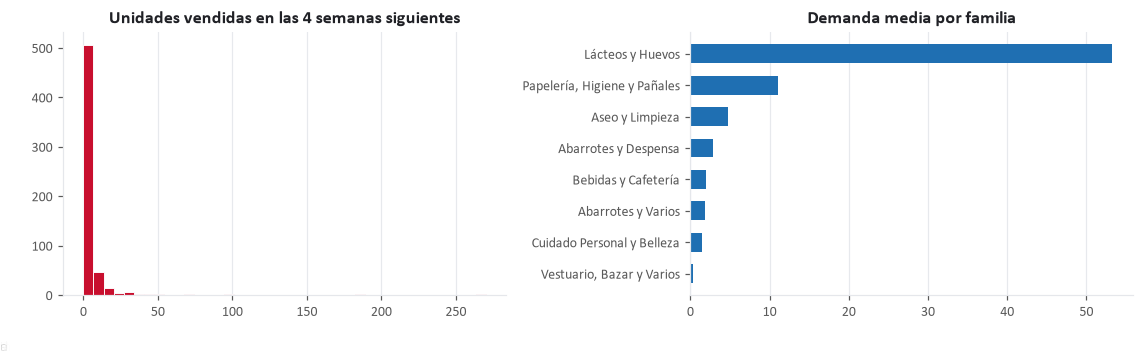

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3))
ax[0].hist(matriz[OBJETIVO], bins=40, color=CAT[0], edgecolor=SUP, linewidth=0.6)
ax[0].set_title("Unidades vendidas en las 4 semanas siguientes")
ax[0].set_xlabel("Unidades"); ax[0].set_ylabel("Productos")

fam = matriz.groupby("familia")[OBJETIVO].mean().sort_values()
ax[1].barh(fam.index, fam.values, color=CAT[1], height=0.6)
ax[1].set_title("Demanda media por familia")
ax[1].set_xlabel("Unidades promedio en 4 semanas")
for a in ax:
    a.grid(axis="x", alpha=0.9); a.set_axisbelow(True)
plt.tight_layout()
plt.savefig(RAIZ / "reports/figuras/h1_objetivo.png")
plt.show()

## 8. Auditoría de la matriz

Las mismas comprobaciones de la ayudantía 3: faltantes, extremos y **sospecha de fuga** por
correlación con la etiqueta (una correlación sobre 0,80 no es una gran variable: es una hipótesis de
fuga que hay que descartar).

In [14]:
# --- faltantes ---
falt = matriz.isna().sum()
falt = falt[falt > 0]
print("Faltantes por variable:")
print(falt.to_string() if len(falt) else "  ninguno")

# --- extremos (tres reglas) ---
def auditar_extremos(df, columnas):
    filas = []
    for c in columnas:
        s = df[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75]); ric = q3 - q1
        z = ((s - s.mean()) / s.std(ddof=0)).abs()
        filas.append({"variable": c, "asimetría": round(float(s.skew()), 2),
                      "z>3": int((z > 3).sum()),
                      "IQR": int(((s < q1 - 1.5 * ric) | (s > q3 + 1.5 * ric)).sum())})
    return pd.DataFrame(filas).sort_values("asimetría", ascending=False)

NUM_COLS = [c for c in CANDIDATAS if c not in CAT_COLS]
print("\nExtremos:")
print(auditar_extremos(matriz, NUM_COLS).to_string(index=False))

# --- correlación con la etiqueta ---
corr = matriz[NUM_COLS].corrwith(matriz[OBJETIVO]).sort_values(key=abs, ascending=False)
print("\nCorrelación con la etiqueta:")
print(corr.round(3).to_string())

Faltantes por variable:
tendencia_4s_12s    88
margen_pct          79

Extremos:
             variable  asimetría  z>3  IQR
              unid_4s       9.68    8   68
             unid_26s       9.67    9   75
             unid_12s       9.45    9   65
          sd_unid_12s       8.50    7   56
         precio_medio       6.67   10   55
     recencia_semanas       1.58    9   52
     tendencia_4s_12s       0.90    0    0
semanas_con_venta_12s       0.80    0    0
           margen_pct      -2.30    9   56
   antiguedad_semanas      -2.58   21   76

Correlación con la etiqueta:
unid_4s                  0.962
unid_26s                 0.960
unid_12s                 0.955
sd_unid_12s              0.848
semanas_con_venta_12s    0.422
recencia_semanas        -0.174
antiguedad_semanas       0.129
margen_pct               0.057
tendencia_4s_12s         0.014
precio_medio             0.002


In [15]:
DECISIONES_MATRIZ = pd.DataFrame([
    {"alerta": "Faltantes en margen_pct (la ausencia separa la etiqueta)",
     "decision": "corrijo",
     "justificacion": "Vienen del costo = 0 del extracto (MAR: dependen de cómo se cargó el producto "
                      "en el sistema). Se imputan por mediana dentro del pipeline; src/modelos.py "
                      "agrega además el indicador de faltante (add_indicator=True)."},
    {"alerta": "Faltantes en tendencia_4s_12s (la ausencia separa la etiqueta)",
     "decision": "corrijo",
     "justificacion": "Productos sin venta en 12 semanas: la razón no se puede calcular (división por "
                      "cero). Mediana dentro del pipeline + indicador de faltante en src/modelos.py."},
    {"alerta": "Extremos en unidades (asimetría alta)",
     "decision": "descarto",
     "justificacion": "Son productos de alta rotación reales (bolsas, huevos, bebidas). Eliminarlos "
                      "sería sacar justo los productos que más importa reponer bien."},
    {"alerta": "Correlación > 0,80 de unid_4s, unid_12s, unid_26s y sd_unid_12s con la etiqueta",
     "decision": "descarto",
     "justificacion": "No es fuga: se calculan con semanas 41-66, todas anteriores a t0. Que la venta "
                      "pasada prediga la futura es esperable en reposición."},
])
print(DECISIONES_MATRIZ.to_string(index=False))

                                                                         alerta decision                                                                                                                                                                                                         justificacion
                       Faltantes en margen_pct (la ausencia separa la etiqueta)  corrijo Vienen del costo = 0 del extracto (MAR: dependen de cómo se cargó el producto en el sistema). Se imputan por mediana dentro del pipeline; src/modelos.py agrega además el indicador de faltante (add_indicator=True).
                 Faltantes en tendencia_4s_12s (la ausencia separa la etiqueta)  corrijo                                                          Productos sin venta en 12 semanas: la razón no se puede calcular (división por cero). Mediana dentro del pipeline + indicador de faltante en src/modelos.py.
                                          Extremos en unidades (asimetría alta) descarto   

### Auditoría empaquetada: `src/auditoria.py` y `reports/auditoria_calidad.md`

Se usa la función `auditar_matriz()` de la ayudantía 3, adaptada a una etiqueta continua. El informe
se guarda junto con la entrega, con las decisiones de esta sección.

In [16]:
CODIGO = '''# -*- coding: utf-8 -*-
"""Auditoría de calidad y de fuga para matrices de diseño · EC2053C.

Adaptada de la ayudantía 3 a una etiqueta CONTINUA (unidades): la brecha de
faltantes se mide en unidades de la etiqueta y no como prevalencia.
"""
from __future__ import annotations
import numpy as np
import pandas as pd

SOSPECHOSAS = ("final", "recuperado", "post", "cierre", "resultado",
               "definitivo", "real", "efectivo", "pagado")


def _extremos(s: pd.Series) -> dict:
    q1, q3 = s.quantile([0.25, 0.75]); ric = q3 - q1
    z = ((s - s.mean()) / s.std(ddof=0)).abs()
    med = s.median(); mad = (s - med).abs().median()
    z_rob = (0.6745 * (s - med) / mad).abs() if mad > 0 else pd.Series(0.0, index=s.index)
    return {"asimetria": float(s.skew()),
            "z3": int((z > 3).sum()),
            "iqr": int(((s < q1 - 1.5 * ric) | (s > q3 + 1.5 * ric)).sum()),
            "mad": int((z_rob > 3.5).sum())}


def auditar_matriz(df: pd.DataFrame, etiqueta: str, claves: list[str],
                   umbral_corr: float = 0.60) -> dict:
    """Devuelve un diccionario con las cuatro auditorías y una lista de alertas."""
    alertas: list[str] = []
    n = len(df)

    # --- estructura -----------------------------------------------------
    dup = int(df.duplicated(subset=claves).sum())
    if dup:
        alertas.append(f"{dup} filas duplicadas por la clave {claves}.")
    constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]

    # --- faltantes ------------------------------------------------------
    falt = []
    for c in df.columns:
        if c == etiqueta:
            continue
        na = int(df[c].isna().sum())
        if na == 0:
            continue
        tiene = df[c].notna()
        brecha = float(df.loc[~tiene, etiqueta].mean() - df.loc[tiene, etiqueta].mean())
        falt.append({"variable": c, "faltan": na, "pct": na / n, "brecha_etiqueta": brecha})
        if abs(brecha) > 0.5:      # media unidad de diferencia en la etiqueta
            alertas.append(
                f"La ausencia de «{c}» separa la etiqueta en {brecha:+.2f} unidades: "
                f"use add_indicator=True.")
    faltantes = pd.DataFrame(falt)

    # --- extremos -------------------------------------------------------
    ext = []
    for c in df.select_dtypes("number").columns:
        if c == etiqueta:
            continue
        s = df[c].dropna()
        if s.nunique() <= 2:
            continue
        d = _extremos(s); d["variable"] = c
        ext.append(d)
    extremos = pd.DataFrame(ext)
    if len(extremos):
        extremos = extremos[["variable", "asimetria", "z3", "iqr", "mad"]]
        extremos = extremos.sort_values("asimetria", ascending=False)

    # --- sospechas de fuga ----------------------------------------------
    por_nombre = [c for c in df.columns
                  if c != etiqueta and any(p in c.lower() for p in SOSPECHOSAS)]
    for c in por_nombre:
        alertas.append(f"El nombre de «{c}» sugiere información posterior a la decisión.")

    num = df.select_dtypes("number").drop(columns=[etiqueta], errors="ignore")
    num = num.loc[:, num.nunique() > 1]
    corr = num.corrwith(df[etiqueta]).abs().sort_values(ascending=False)
    altas = corr[corr > umbral_corr]
    for c, v in altas.items():
        alertas.append(f"«{c}» correlaciona {v:.2f} con la etiqueta: descarte fuga antes de usarla.")

    return {"n_filas": n, "n_columnas": df.shape[1],
            "media_etiqueta": float(df[etiqueta].mean()),
            "duplicados_clave": dup, "constantes": constantes,
            "faltantes": faltantes, "extremos": extremos,
            "correlaciones": corr, "sospechosas_por_nombre": por_nombre,
            "alertas": alertas}


def informe_markdown(rep: dict, titulo: str = "Informe de auditoría") -> str:
    """Convierte el resultado de auditar_matriz() en un informe legible."""
    L = [f"# {titulo}", ""]
    L += [f"- Filas: **{rep['n_filas']:,}**  ·  Columnas: **{rep['n_columnas']}**",
          f"- Media de la etiqueta: **{rep['media_etiqueta']:.2f} unidades**",
          f"- Duplicados por clave: **{rep['duplicados_clave']}**",
          f"- Columnas constantes: {rep['constantes'] or 'ninguna'}", ""]

    L += ["## Alertas", ""]
    if rep["alertas"]:
        L += [f"{i}. {a}" for i, a in enumerate(rep["alertas"], 1)]
    else:
        L += ["Ninguna alerta automática. Esto no reemplaza la revisión manual del "
              "diccionario de variables."]
    L += [""]

    if len(rep["faltantes"]):
        L += ["## Faltantes", "", rep["faltantes"].round(3).to_markdown(index=False), ""]
    if len(rep["extremos"]):
        L += ["## Valores extremos", "",
              rep["extremos"].round(2).head(12).to_markdown(index=False), ""]

    L += ["## Correlación con la etiqueta (10 mayores)", "",
          rep["correlaciones"].head(10).round(3).to_markdown(), ""]
    return chr(10).join(L)
'''

destino = RAIZ / "src/auditoria.py"
destino.write_text(CODIGO, encoding="utf-8")
print("Escrito:", destino, f"({len(CODIGO.splitlines())} líneas)")

Escrito: C:\Users\Jose\EC2053C-Ayudantia-01\src\auditoria.py (115 líneas)


In [17]:
import sys, importlib
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
import auditoria
importlib.reload(auditoria)
from auditoria import auditar_matriz, informe_markdown

reporte = auditar_matriz(matriz, etiqueta=OBJETIVO, claves=CLAVES)
print(f"Alertas encontradas: {len(reporte['alertas'])}\n")
for i, al in enumerate(reporte["alertas"], 1):
    print(f"  {i}. {al}")

texto = informe_markdown(reporte, titulo="Auditoría de calidad · matriz de reposición · EC2053C")
texto += "\n## Decisiones sobre las alertas\n\n" + DECISIONES_EXTRACTO.to_markdown(index=False)
texto += "\n\n" + DECISIONES_MATRIZ.to_markdown(index=False) + "\n"
(RAIZ / "reports/auditoria_calidad.md").write_text(texto, encoding="utf-8")
print("\nGuardado: reports/auditoria_calidad.md")

Alertas encontradas: 6

  1. La ausencia de «tendencia_4s_12s» separa la etiqueta en -4.62 unidades: use add_indicator=True.
  2. La ausencia de «margen_pct» separa la etiqueta en -4.01 unidades: use add_indicator=True.
  3. «unid_4s» correlaciona 0.96 con la etiqueta: descarte fuga antes de usarla.
  4. «unid_26s» correlaciona 0.96 con la etiqueta: descarte fuga antes de usarla.
  5. «unid_12s» correlaciona 0.96 con la etiqueta: descarte fuga antes de usarla.
  6. «sd_unid_12s» correlaciona 0.85 con la etiqueta: descarte fuga antes de usarla.

Guardado: reports/auditoria_calidad.md


## 9. Protocolo experimental

Se declara **antes** de modelar y no se cambia después:

| Elemento | Valor |
|---|---|
| Partición | **70% entrenamiento / 30% prueba**, aleatoria, `random_state = 2053` |
| Selección de modelo y de α | Validación cruzada de **5 pliegues** sólo dentro del 70% |
| Conjunto de prueba | Se abre **una sola vez**, en la sección 13 |
| Transformaciones | Imputación y estandarización **dentro del pipeline** (dentro del pliegue) |
| Métrica principal | **MAE en unidades** (se reporta también RMSE y R²) |

**Por qué MAE.** El costo de equivocarse en la reposición es proporcional a las unidades que faltan o
sobran: cada unidad faltante es un margen perdido. El MAE se lee directamente como *"en promedio me
equivoco en X unidades por producto"*. El RMSE castiga mucho más los errores grandes y se deja como
complemento.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import cross_validate, KFold, train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = matriz[CANDIDATAS]
y = matriz[OBJETIVO]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print(f"Entrenamiento : {len(X_tr):,} productos ({len(X_tr)/len(X):.0%})")
print(f"Prueba        : {len(X_te):,} productos ({len(X_te)/len(X):.0%})  ← no se toca hasta la sección 13")

CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

Entrenamiento : 409 productos (70%)
Prueba        : 176 productos (30%)  ← no se toca hasta la sección 13


## 10. Línea base

Mismo protocolo de la ayudantía 4: la función `evaluar()` corre validación cruzada **sólo en
entrenamiento**. Se agregan dos referencias que todo modelo debe superar:

- **Predecir siempre la media** (modelo trivial del curso).
- **Regla actual del negocio**: *"pido lo mismo que vendí las últimas 4 semanas"*. Es lo que el
  encargado hace hoy sin modelo.

In [19]:
def preprocesador(cols_num):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("esc", StandardScaler())]), cols_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh",  OneHotEncoder(handle_unknown="ignore"))]), CAT_COLS),
    ])

def evaluar(est, etiqueta, cols=None):
    cols = NUM_COLS if cols is None else cols
    pipe = Pipeline([("pre", preprocesador(cols)), ("reg", est)])
    r = cross_validate(pipe, X_tr, y_tr, cv=CV, return_train_score=True,
                       scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    return {"modelo": etiqueta,
            "MAE":  -r["test_neg_mean_absolute_error"].mean(),
            "RMSE": -r["test_neg_root_mean_squared_error"].mean(),
            "R² prueba":  r["test_r2"].mean(),
            "R² entren.": r["train_r2"].mean(),
            "sd R²": r["test_r2"].std()}

# regla actual: predicción = unid_4s, evaluada en los mismos 5 pliegues (sólo la parte de validación)
def evaluar_regla():
    mae, rmse, r2 = [], [], []
    for _, idx_va in CV.split(X_tr):
        yv, pv = y_tr.iloc[idx_va], X_tr.iloc[idx_va]["unid_4s"]
        mae.append(mean_absolute_error(yv, pv))
        rmse.append(np.sqrt(mean_squared_error(yv, pv)))
        r2.append(r2_score(yv, pv))
    return {"modelo": "Regla actual (repetir últimas 4 sem.)", "MAE": np.mean(mae),
            "RMSE": np.mean(rmse), "R² prueba": np.mean(r2), "R² entren.": np.nan, "sd R²": np.std(r2)}

linea_cero = evaluar(DummyRegressor(strategy="mean"), "Predecir siempre la media")
regla = evaluar_regla()
base = evaluar(LinearRegression(), "OLS · 11 variables")

tabla_base = pd.DataFrame([linea_cero, regla, base])
print(tabla_base.round(3).to_string(index=False))
print("\nRegla del curso: toda comparación empieza con el modelo trivial.")

                               modelo   MAE   RMSE  R² prueba  R² entren.  sd R²
            Predecir siempre la media 5.320 14.835     -0.034       0.000  0.047
Regla actual (repetir últimas 4 sem.) 1.880  4.367      0.743         NaN  0.233
                   OLS · 11 variables 2.132  5.614      0.694       0.958  0.250

Regla del curso: toda comparación empieza con el modelo trivial.


## 11. Multicolinealidad (VIF)

Las variables de venta pasada (`unid_4s`, `unid_12s`, `unid_26s`, `sd_unid_12s`) miden casi lo mismo
en distintos horizontes: es colinealidad **por construcción**, igual que en la cátedra.

In [20]:
def vif(matriz_num):
    Z = pd.DataFrame(StandardScaler().fit_transform(
        SimpleImputer(strategy="median").fit_transform(matriz_num)), columns=matriz_num.columns)
    out = {}
    for c in Z.columns:
        otras = Z.drop(columns=c)
        r2 = LinearRegression().fit(otras, Z[c]).score(otras, Z[c])
        out[c] = np.inf if r2 >= 1 - 1e-12 else 1.0 / (1.0 - r2)
    return pd.Series(out).sort_values(ascending=False)

vif_base = vif(X_tr[NUM_COLS])
print(vif_base.round(2).to_string())
print(f"\nVariables con VIF > 10: {(vif_base > 10).sum()} de {len(vif_base)}")

unid_12s                 186.70
unid_26s                 147.75
unid_4s                   48.51
sd_unid_12s               18.80
semanas_con_venta_12s      2.68
recencia_semanas           2.04
tendencia_4s_12s           1.32
antiguedad_semanas         1.25
precio_medio               1.07
margen_pct                 1.03

Variables con VIF > 10: 4 de 10


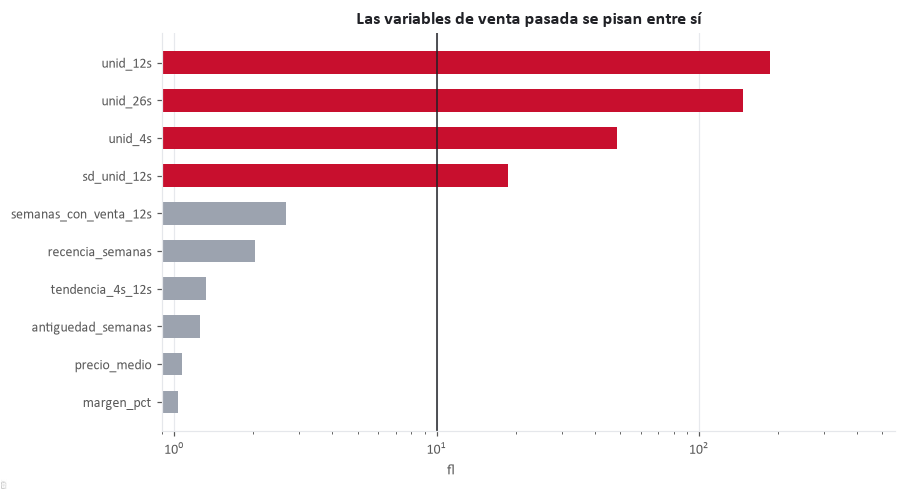

In [21]:
fig, ax = plt.subplots(figsize=(8.6, 0.34 * len(vif_base) + 1.3))
orden = vif_base.sort_values()
barras = ax.barh(orden.index, orden.values, height=0.6,
                 color=[CAT[0] if v > 10 else TENUE for v in orden.values])
for b, v in zip(barras, orden.values):
    ax.text(v * 1.08, b.get_y() + b.get_height() / 2, f"{v:,.1f}", va="center", fontsize=8.5, color=SECUND)
ax.axvline(10, color=TINTA, linewidth=1)
ax.set_xscale("log")
ax.set_xlim(0.9, orden.max() * 3)
ax.set_xlabel("Factor de inflación de varianza (escala logarítmica)")
ax.set_title("Las variables de venta pasada se pisan entre sí")
ax.grid(axis="x", alpha=0.9); ax.set_axisbelow(True)
plt.savefig(RAIZ / "reports/figuras/h1_vif.png")
plt.show()

In [22]:
DECISIONES_VIF = pd.DataFrame([
    {"variable": v, "vif": round(float(vif_base[v]), 1), "salida": "Regularizar",
     "justificacion": "Es una de las medidas de venta pasada. Todas aportan algo (reciente vs. "
                      "largo plazo) y ninguna es derivada exacta de otra: se conservan y se usa Ridge."}
    for v in vif_base[vif_base > 10].index
])
print(DECISIONES_VIF.to_string(index=False))
VALIDAS = {"Dejarla", "Eliminar una del par", "Combinarlas", "Regularizar"}
assert set(DECISIONES_VIF["salida"]) <= VALIDAS

   variable   vif      salida                                                                                                                                           justificacion
   unid_12s 186.7 Regularizar Es una de las medidas de venta pasada. Todas aportan algo (reciente vs. largo plazo) y ninguna es derivada exacta de otra: se conservan y se usa Ridge.
   unid_26s 147.8 Regularizar Es una de las medidas de venta pasada. Todas aportan algo (reciente vs. largo plazo) y ninguna es derivada exacta de otra: se conservan y se usa Ridge.
    unid_4s  48.5 Regularizar Es una de las medidas de venta pasada. Todas aportan algo (reciente vs. largo plazo) y ninguna es derivada exacta de otra: se conservan y se usa Ridge.
sd_unid_12s  18.8 Regularizar Es una de las medidas de venta pasada. Todas aportan algo (reciente vs. largo plazo) y ninguna es derivada exacta de otra: se conservan y se usa Ridge.


## 12. Regularización: Ridge vs Lasso

El α no se elige a mano: lo eligen `RidgeCV` y `LassoCV` con validación cruzada **dentro** del pipeline.

In [23]:
grid = np.logspace(-3, 4, 50)

comparacion = pd.DataFrame([
    linea_cero, regla, base,
    evaluar(RidgeCV(alphas=grid), "Ridge (α por CV)"),
    evaluar(LassoCV(alphas=grid, max_iter=50000, random_state=SEED), "Lasso (α por CV)"),
])
comparacion["brecha"] = (comparacion["R² entren."] - comparacion["R² prueba"]).round(3)
print(comparacion.round(3).to_string(index=False))

                               modelo   MAE   RMSE  R² prueba  R² entren.  sd R²  brecha
            Predecir siempre la media 5.320 14.835     -0.034       0.000  0.047   0.034
Regla actual (repetir últimas 4 sem.) 1.880  4.367      0.743         NaN  0.233     NaN
                   OLS · 11 variables 2.132  5.614      0.694       0.958  0.250   0.264
                     Ridge (α por CV) 2.025  5.363      0.728       0.956  0.233   0.228
                     Lasso (α por CV) 2.062  5.629      0.710       0.957  0.236   0.248


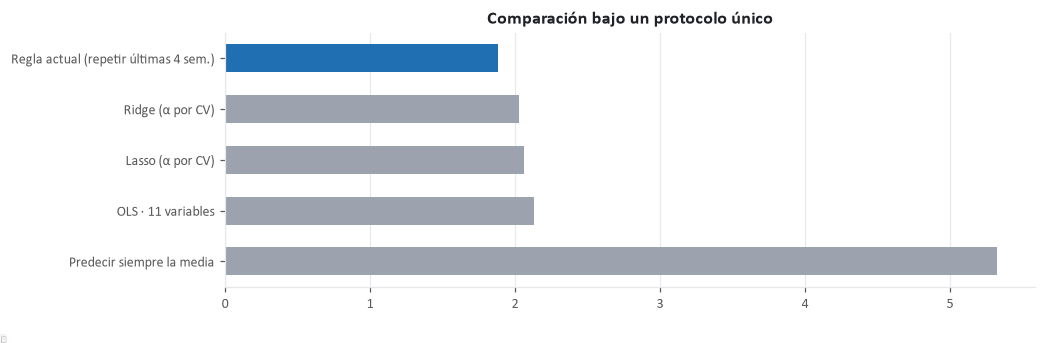

In [24]:
fig, ax = plt.subplots(figsize=(9.5, 3.0))
orden = comparacion.sort_values("MAE", ascending=False).reset_index(drop=True)
mejor = orden["MAE"].idxmin()
barras = ax.barh(orden["modelo"], orden["MAE"], height=0.55,
                 color=[CAT[1] if i == mejor else TENUE for i in orden.index])
for b, v in zip(barras, orden["MAE"]):
    ax.text(v + 0.05, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center",
            fontsize=10, fontweight="bold", color=TINTA)
ax.set_xlabel("MAE en validación cruzada (unidades por producto) · menor es mejor")
ax.set_title("Comparación bajo un protocolo único")
ax.grid(axis="x", alpha=0.9); ax.set_axisbelow(True)
plt.savefig(RAIZ / "reports/figuras/h1_comparacion.png")
plt.show()

**Lectura honesta.** En validación cruzada la *regla actual* (repetir las últimas 4 semanas) queda
levemente mejor que Ridge en MAE (1,88 vs 2,02 unidades), pero la diferencia es menor que la variación
entre pliegues (desviación del R² ≈ 0,23). Entre los modelos de regresión, **Ridge es el mejor**: le
gana a OLS y a Lasso, y tiene la menor brecha entre entrenamiento y validación. La prueba final
(sección 13) dirá si Ridge supera a la regla actual en datos que nunca vio.

### Estabilidad de los coeficientes entre pliegues

Lo que Ridge "compra" aquí no es tanto exactitud como **coeficientes estables**: con OLS, las
variables colineales reparten el efecto de forma arbitraria y cambian de un pliegue a otro.

In [25]:
def coef_por_pliegue(est):
    filas = []
    for idx_tr, _ in CV.split(X_tr):
        p = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler()),
                      ("reg", est)]).fit(X_tr.iloc[idx_tr][NUM_COLS], y_tr.iloc[idx_tr])
        filas.append(pd.Series(p.named_steps["reg"].coef_, index=NUM_COLS))
    return pd.DataFrame(filas)

alpha_ridge = Pipeline([("pre", preprocesador(NUM_COLS)),
                        ("reg", RidgeCV(alphas=grid))]).fit(X_tr, y_tr).named_steps["reg"].alpha_
coef_ols   = coef_por_pliegue(LinearRegression())
coef_ridge = coef_por_pliegue(Ridge(alpha=alpha_ridge))

estab = pd.DataFrame({"OLS · sd entre pliegues": coef_ols.std(),
                      "Ridge · sd entre pliegues": coef_ridge.std()}).round(3)
print(f"α elegido para Ridge: {alpha_ridge:.2f}\n")
print(estab.sort_values("OLS · sd entre pliegues", ascending=False).to_string())
for v in ["unid_4s", "unid_12s", "unid_26s"]:
    print(f"{v:<10}: Ridge reduce la inestabilidad {coef_ols[v].std() / coef_ridge[v].std():.1f} veces")

α elegido para Ridge: 7.20

                       OLS · sd entre pliegues  Ridge · sd entre pliegues
unid_12s                                 9.683                      1.360
unid_26s                                 7.542                      1.444
unid_4s                                  5.063                      2.066
sd_unid_12s                              2.911                      2.064
semanas_con_venta_12s                    0.406                      0.445
recencia_semanas                         0.325                      0.248
tendencia_4s_12s                         0.240                      0.105
antiguedad_semanas                       0.054                      0.027
margen_pct                               0.038                      0.022
precio_medio                             0.026                      0.042
unid_4s   : Ridge reduce la inestabilidad 2.5 veces
unid_12s  : Ridge reduce la inestabilidad 7.1 veces
unid_26s  : Ridge reduce la inestabilidad 5.2 veces


In [26]:
pipe_lasso = Pipeline([("pre", preprocesador(NUM_COLS)),
                       ("reg", LassoCV(alphas=grid, max_iter=50000, random_state=SEED))]).fit(X_tr, y_tr)
nombres = [n.split("__")[-1] for n in pipe_lasso.named_steps["pre"].get_feature_names_out()]
coef_lasso = pd.Series(pipe_lasso.named_steps["reg"].coef_, index=nombres)
anuladas = coef_lasso[coef_lasso.abs() < 1e-9].index.tolist()
print(f"α elegido para Lasso: {pipe_lasso.named_steps['reg'].alpha_:.3f}")
print(f"Variables que Lasso anula: {len(anuladas)} de {len(coef_lasso)}")
print(anuladas)

α elegido para Lasso: 0.019
Variables que Lasso anula: 7 de 18
['precio_medio', 'familia_Abarrotes y Despensa', 'familia_Abarrotes y Varios', 'familia_Bebidas y Cafetería', 'familia_Cuidado Personal y Belleza', 'familia_Lácteos y Huevos', 'familia_Vestuario, Bazar y Varios']


### Por qué Ridge y no Lasso

| Criterio | Ridge | Lasso |
|---|---|---|
| Variables de venta pasada muy correlacionadas (VIF > 10) | Las conserva todas y reparte el efecto; reduce entre 2,5 y 7 veces la inestabilidad de sus coeficientes | Tiende a quedarse con **una** del grupo; cuál elige puede cambiar con otra muestra |
| Qué sabemos del negocio | Todas las medidas de venta aportan (lo reciente y lo de largo plazo) | Supone que pocas variables explican casi todo |
| Exactitud (MAE en CV) | 2,02 unidades | 2,06 unidades (prácticamente igual) |
| Qué anula | Nada | 7 de 18 columnas: el precio y casi todas las familias |
| Explicación en una reunión | "Todas cuentan, ninguna se exagera" | "Esta variable no importa" — falso: es redundante, no irrelevante |
| Variables candidatas | Sólo 11: no necesitamos que el modelo seleccione | Su ventaja (seleccionar) sirve cuando hay muchas |

Elastic Net se descarta para este hito por simplicidad: agrega un segundo hiperparámetro (`l1_ratio`) y
con 11 variables no hay nada que seleccionar.

## 13. Evaluación final en el conjunto de prueba (se abre una sola vez)

Se reentrena cada modelo con **todo el 70%** y se evalúa en el 30% que no se ha tocado.

In [27]:
def ajustar(est):
    return Pipeline([("pre", preprocesador(NUM_COLS)), ("reg", est)]).fit(X_tr, y_tr)

modelos_finales = {
    "Predecir siempre la media": ajustar(DummyRegressor(strategy="mean")),
    "OLS": ajustar(LinearRegression()),
    "Ridge": ajustar(RidgeCV(alphas=grid)),
}
preds = {n: np.clip(m.predict(X_te), 0, None) for n, m in modelos_finales.items()}   # no hay demanda negativa
preds["Regla actual"] = X_te["unid_4s"].to_numpy()

final = pd.DataFrame([{
    "modelo": n,
    "MAE (unid.)":  mean_absolute_error(y_te, p),
    "RMSE (unid.)": np.sqrt(mean_squared_error(y_te, p)),
    "R²": r2_score(y_te, p)} for n, p in preds.items()]).sort_values("MAE (unid.)")
print(final.round(3).to_string(index=False))

mae_ridge = final.loc[final["modelo"] == "Ridge", "MAE (unid.)"].iloc[0]
mae_regla = final.loc[final["modelo"] == "Regla actual", "MAE (unid.)"].iloc[0]
print(f"\nRidge reduce el error de la regla actual en {1 - mae_ridge / mae_regla:.1%} "
      f"({mae_regla:.2f} → {mae_ridge:.2f} unidades por producto).")

                   modelo  MAE (unid.)  RMSE (unid.)     R²
                    Ridge        1.544         2.478  0.948
                      OLS        1.737         3.563  0.893
             Regla actual        1.920         3.895  0.872
Predecir siempre la media        5.147        10.902 -0.000

Ridge reduce el error de la regla actual en 19.6% (1.92 → 1.54 unidades por producto).


## 14. Ecuación fundamental y los coeficientes en lenguaje de negocio

$$
\widehat{\text{unid\_prox\_4s}}_i = \beta_0 + \sum_{j=1}^{10} \beta_j \, z_{ij} + \sum_{f} \gamma_f \, \text{familia}_{if}
$$

donde $z_{ij}$ es la variable $j$ **estandarizada** del producto $i$. Ridge elige los $\beta$ que minimizan

$$
\sum_i \left(y_i - \hat y_i\right)^2 + \alpha \sum_j \beta_j^2
$$

Lectura: *"si la variable sube una desviación estándar, la demanda esperada del próximo mes cambia en
β unidades, manteniendo lo demás igual"*.

In [28]:
ridge_final = modelos_finales["Ridge"]
nombres = [n.split("__")[-1] for n in ridge_final.named_steps["pre"].get_feature_names_out()]
coef = pd.Series(ridge_final.named_steps["reg"].coef_, index=nombres)
beta0 = ridge_final.named_steps["reg"].intercept_
print(f"α elegido por CV : {ridge_final.named_steps['reg'].alpha_:.2f}")
print(f"Intercepto β0    : {beta0:.3f} unidades\n")

tabla_coef = coef.sort_values(key=abs, ascending=False).round(3)
for v, c in tabla_coef.head(8).items():
    signo = "más" if c >= 0 else "menos"
    if v.startswith("familia_"):
        print(f"{v:<38} {c:+8.3f}  ·  ser de «{v[8:]}» se asocia con {abs(c):.2f} unidades {signo}")
    else:
        print(f"{v:<38} {c:+8.3f}  ·  una desv. est. más se asocia con {abs(c):.2f} unidades {signo}")

α elegido por CV : 7.20
Intercepto β0    : 4.364 unidades

unid_4s                                  +7.952  ·  una desv. est. más se asocia con 7.95 unidades más
unid_26s                                 +6.690  ·  una desv. est. más se asocia con 6.69 unidades más
unid_12s                                 +5.841  ·  una desv. est. más se asocia con 5.84 unidades más
sd_unid_12s                              -3.395  ·  una desv. est. más se asocia con 3.40 unidades menos
familia_Lácteos y Huevos                 +0.949  ·  ser de «Lácteos y Huevos» se asocia con 0.95 unidades más
semanas_con_venta_12s                    -0.880  ·  una desv. est. más se asocia con 0.88 unidades menos
familia_Papelería, Higiene y Pañales     -0.601  ·  ser de «Papelería, Higiene y Pañales» se asocia con 0.60 unidades menos
recencia_semanas                         -0.564  ·  una desv. est. más se asocia con 0.56 unidades menos


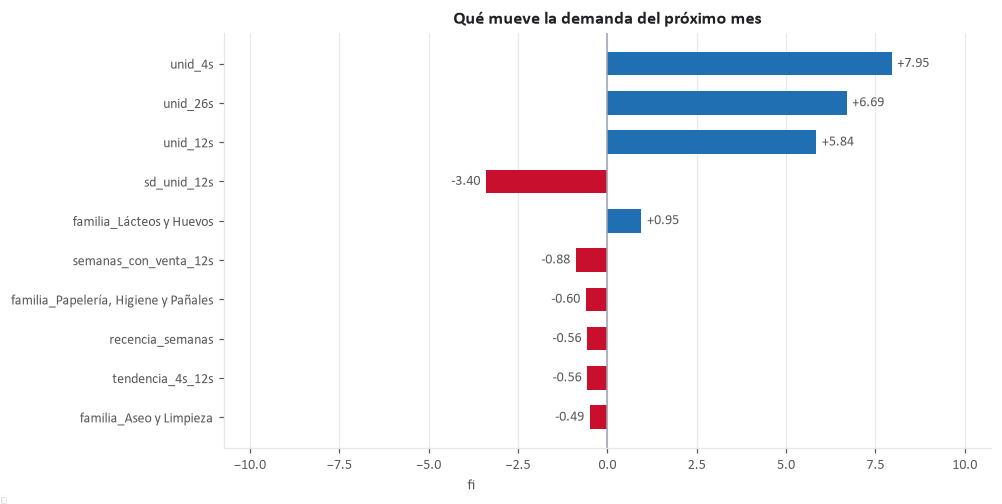

In [29]:
top = tabla_coef.head(10).sort_values(key=abs)
fig, ax = plt.subplots(figsize=(9, 0.36 * len(top) + 1.3))
barras = ax.barh(top.index, top.values, color=[CAT[1] if v >= 0 else CAT[0] for v in top.values], height=0.6)
lim = max(abs(top.values)) * 1.35
for b, v in zip(barras, top.values):
    ax.text(v + (lim * 0.015 if v >= 0 else -lim * 0.015), b.get_y() + b.get_height() / 2,
            f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=SECUND)
ax.axvline(0, color=TENUE, linewidth=1)
ax.set_xlim(-lim, lim)
ax.set_xlabel("Coeficiente Ridge (unidades por desviación estándar)")
ax.set_title("Qué mueve la demanda del próximo mes")
ax.grid(axis="x", alpha=0.9); ax.set_axisbelow(True)
plt.savefig(RAIZ / "reports/figuras/h1_coeficientes.png")
plt.show()

## 15. Diagnóstico (cuatro gráficos)

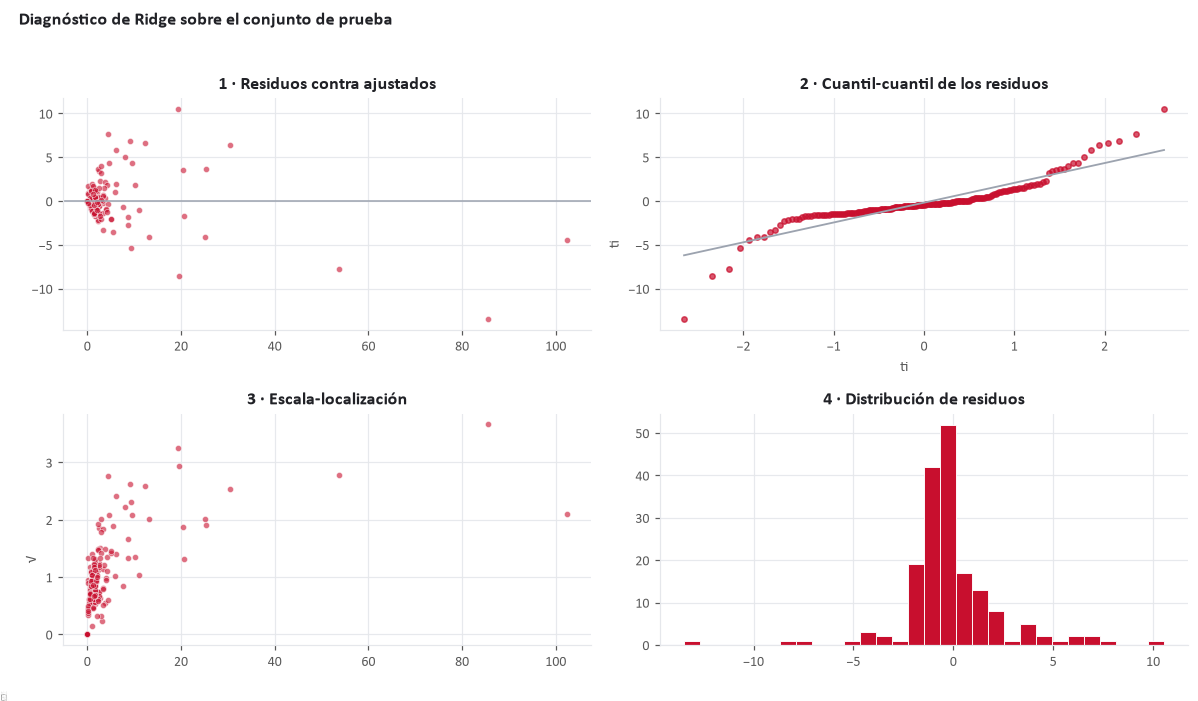

media_residuo   -0.184
sd_residuo       2.471
asimetría       -0.091


In [30]:
from scipy import stats

pred_te = preds["Ridge"]
resid = y_te.to_numpy() - pred_te

fig, ax = plt.subplots(2, 2, figsize=(11, 6.2))
ax[0, 0].scatter(pred_te, resid, s=16, color=CAT[0], alpha=0.6, edgecolor=SUP, linewidth=0.5)
ax[0, 0].axhline(0, color=TENUE, linewidth=1)
ax[0, 0].set_title("1 · Residuos contra ajustados")
ax[0, 0].set_xlabel("Ajustado (unid.)"); ax[0, 0].set_ylabel("Residuo (unid.)")

stats.probplot(resid, dist="norm", plot=ax[0, 1])
ax[0, 1].get_lines()[0].set(marker="o", markersize=3.5, color=CAT[0], alpha=0.7, linestyle="none")
ax[0, 1].get_lines()[1].set(color=TENUE, linewidth=1.2)
ax[0, 1].set_title("2 · Cuantil-cuantil de los residuos")
ax[0, 1].set_xlabel("Cuantiles teóricos"); ax[0, 1].set_ylabel("Cuantiles observados")

ax[1, 0].scatter(pred_te, np.sqrt(np.abs(resid)), s=16, color=CAT[0], alpha=0.6, edgecolor=SUP, linewidth=0.5)
ax[1, 0].set_title("3 · Escala-localización")
ax[1, 0].set_xlabel("Ajustado (unid.)"); ax[1, 0].set_ylabel("√|residuo|")

ax[1, 1].hist(resid, bins=30, color=CAT[0], edgecolor=SUP, linewidth=0.6)
ax[1, 1].set_title("4 · Distribución de residuos")
ax[1, 1].set_xlabel("Residuo (unid.)"); ax[1, 1].set_ylabel("Productos")

for a in ax.ravel():
    a.grid(alpha=0.9); a.set_axisbelow(True)
fig.suptitle("Diagnóstico de Ridge sobre el conjunto de prueba", fontsize=12, fontweight="bold",
             color=TINTA, y=1.02, x=0.02, ha="left")
plt.tight_layout()
plt.savefig(RAIZ / "reports/figuras/h1_diagnostico.png")
plt.show()
print(pd.Series({"media_residuo": resid.mean(), "sd_residuo": resid.std(),
                 "asimetría": float(pd.Series(resid).skew())}).round(3).to_string())

In [31]:
LECTURA_DIAGNOSTICO = {
    "1 · residuos vs ajustados": "Embudo: el error crece con el tamaño del producto (los de alta rotación fallan en más unidades).",
    "2 · cuantil-cuantil":       "Colas pesadas en ambos extremos: hay semanas de venta atípica (promociones, quiebres).",
    "3 · escala-localización":   "La dispersión sube con el nivel: varianza no constante.",
    "4 · histograma":            "Centrado en cero y simétrico al centro, con colas largas.",
    "decisión":                  "Para el Hito 1 se sigue en unidades (así se compra). En el informe final se probará "
                                 "apilar varios cortes t0 para tener más filas.",
}
for k, v in LECTURA_DIAGNOSTICO.items():
    print(f"{k:<28}: {v}")

1 · residuos vs ajustados   : Embudo: el error crece con el tamaño del producto (los de alta rotación fallan en más unidades).
2 · cuantil-cuantil         : Colas pesadas en ambos extremos: hay semanas de venta atípica (promociones, quiebres).
3 · escala-localización     : La dispersión sube con el nivel: varianza no constante.
4 · histograma              : Centrado en cero y simétrico al centro, con colas largas.
decisión                    : Para el Hito 1 se sigue en unidades (así se compra). En el informe final se probará apilar varios cortes t0 para tener más filas.


## 16. Costo del error en pesos

El error no cuesta lo mismo hacia arriba que hacia abajo:

| Error | Qué pasa | Costo por unidad (supuesto) |
|---|---|---|
| **Pedir de menos** (predicción < venta real) | Quiebre de stock: se pierde la venta | **Margen unitario** = precio − costo |
| **Pedir de más** (predicción > venta real) | Unidad parada un mes en bodega | **5% del costo** (capital inmovilizado + merma) |

El 5% es un supuesto que hay que validar con el dueño del minimarket.

In [32]:
TASA_SOBRESTOCK = 0.05

te = X_te[["precio_medio", "margen_pct"]].copy()
te["margen_pct"] = te["margen_pct"].fillna(X_tr["margen_pct"].median())
te["margen_unit"] = te["precio_medio"] * te["margen_pct"]
te["costo_unit"]  = te["precio_medio"] - te["margen_unit"]

def costo_pesos(pred):
    falta = np.clip(y_te.to_numpy() - pred, 0, None)
    sobra = np.clip(pred - y_te.to_numpy(), 0, None)
    return float((falta * te["margen_unit"]).sum() + (sobra * te["costo_unit"] * TASA_SOBRESTOCK).sum())

costos = pd.DataFrame([{"modelo": n, "costo_total_$": costo_pesos(p)} for n, p in preds.items()])
costos["costo_por_producto_$"] = costos["costo_total_$"] / len(y_te)
costos = costos.sort_values("costo_total_$")
print(f"Margen unitario mediano : ${te['margen_unit'].median():,.0f}")
print(f"Costo de sobrestock med.: ${(te['costo_unit'] * TASA_SOBRESTOCK).median():,.0f} por unidad\n")
print(costos.round(0).to_string(index=False))

ahorro = (costos.loc[costos["modelo"] == "Regla actual", "costo_total_$"].iloc[0]
          - costos.loc[costos["modelo"] == "Ridge", "costo_total_$"].iloc[0])
print(f"\nAhorro de Ridge frente a la regla actual en {len(y_te)} productos de prueba, "
      f"un ciclo de 4 semanas: ${ahorro:,.0f}")

Margen unitario mediano : $410
Costo de sobrestock med.: $80 por unidad

                   modelo  costo_total_$  costo_por_producto_$
                    Ridge        69074.0                 392.0
                      OLS        80796.0                 459.0
             Regla actual        88605.0                 503.0
Predecir siempre la media       247366.0                1405.0

Ahorro de Ridge frente a la regla actual en 176 productos de prueba, un ciclo de 4 semanas: $19,531


## 17. Empaquetar: `src/modelos.py`

Como en la ayudantía 4, las funciones de comparación quedan en `src/modelos.py` para reutilizarlas
en el informe final. Se vuelve a correr la comparación sobre el 70% de entrenamiento. Los números
pueden diferir en decimales de la sección 12 porque este módulo agrega un indicador de faltante
(`add_indicator=True`); el orden de los modelos se mantiene.

In [33]:
CODIGO = '''# -*- coding: utf-8 -*-
"""Comparación de modelos bajo protocolo único · EC2053C."""
from __future__ import annotations
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, KFold
from sklearn.dummy import DummyRegressor

SEMILLA = 2053


def preprocesador(cols_num, cols_cat, grado: int = 1) -> ColumnTransformer:
    pasos = [("imp", SimpleImputer(strategy="median", add_indicator=True)),
             ("esc", StandardScaler())]
    if grado > 1:
        pasos.insert(1, ("poly", PolynomialFeatures(degree=grado, include_bias=False)))
    return ColumnTransformer([
        ("num", Pipeline(pasos), cols_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cols_cat),
    ])


def vif(matriz_num: pd.DataFrame) -> pd.Series:
    """Factor de inflación de varianza por variable."""
    Z = pd.DataFrame(
        StandardScaler().fit_transform(
            SimpleImputer(strategy="median").fit_transform(matriz_num)),
        columns=matriz_num.columns)
    salida = {}
    for c in Z.columns:
        otras = Z.drop(columns=c)
        r2 = LinearRegression().fit(otras, Z[c]).score(otras, Z[c])
        salida[c] = np.inf if r2 >= 1 - 1e-12 else 1.0 / (1.0 - r2)
    return pd.Series(salida).sort_values(ascending=False)


def comparar_modelos(X, y, modelos: dict, cols_num, cols_cat,
                     grado: int = 1, escala: float = 1.0,
                     n_pliegues: int = 5, incluir_trivial: bool = True) -> pd.DataFrame:
    """Evalúa varios estimadores sobre el mismo protocolo y devuelve una tabla.

    modelos: {"nombre": estimador}. Se agrega siempre el modelo trivial como
    referencia, salvo que se pida lo contrario.
    """
    cv = KFold(n_splits=n_pliegues, shuffle=True, random_state=SEMILLA)
    candidatos = dict(modelos)
    if incluir_trivial:
        candidatos = {"Media (línea cero)": DummyRegressor(strategy="mean"), **candidatos}

    filas = []
    for nombre, est in candidatos.items():
        pipe = Pipeline([("pre", preprocesador(cols_num, cols_cat, grado)), ("reg", est)])
        r = cross_validate(pipe, X, y, cv=cv, return_train_score=True,
                           scoring=["neg_root_mean_squared_error",
                                    "neg_mean_absolute_error", "r2"])
        filas.append({
            "modelo": nombre,
            "RMSE": -r["test_neg_root_mean_squared_error"].mean() / escala,
            "MAE": -r["test_neg_mean_absolute_error"].mean() / escala,
            "R2_prueba": r["test_r2"].mean(),
            "R2_entrenamiento": r["train_r2"].mean(),
            "sd_R2": r["test_r2"].std(),
        })
    out = pd.DataFrame(filas)
    out["brecha"] = out["R2_entrenamiento"] - out["R2_prueba"]
    return out


def filas_por_variable(X, cols_num, cols_cat, grado: int = 1) -> dict:
    """Diagnóstico de dimensionalidad: cuántas filas hay por variable efectiva."""
    pre = preprocesador(cols_num, cols_cat, grado).fit(X)
    p = len(pre.get_feature_names_out())
    n = len(X)
    if n / p < 10:
        veredicto = "regularizar no es opcional"
    elif n / p < 25:
        veredicto = "comparar con y sin regularizacion"
    else:
        veredicto = "zona comoda"
    return {"filas": n, "variables": p, "razon": round(n / p, 1), "veredicto": veredicto}
'''

destino = RAIZ / "src/modelos.py"
destino.write_text(CODIGO, encoding="utf-8")
print("Escrito:", destino, f"({len(CODIGO.splitlines())} líneas)")

Escrito: C:\Users\Jose\EC2053C-Ayudantia-01\src\modelos.py (86 líneas)


In [34]:
import modelos as mod
importlib.reload(mod)

tabla = mod.comparar_modelos(
    X_tr, y_tr,
    {"OLS": LinearRegression(),
     "Ridge": RidgeCV(alphas=grid),
     "Lasso": LassoCV(alphas=grid, max_iter=50000, random_state=SEED)},
    cols_num=NUM_COLS, cols_cat=CAT_COLS)
print(tabla.round(3).to_string(index=False))
print()
print(mod.filas_por_variable(X_tr, NUM_COLS, CAT_COLS))

            modelo   RMSE   MAE  R2_prueba  R2_entrenamiento  sd_R2  brecha
Media (línea cero) 14.835 5.320     -0.034             0.000  0.047   0.034
               OLS  5.621 2.137      0.694             0.958  0.251   0.265
             Ridge  5.367 2.026      0.728             0.956  0.233   0.229
             Lasso  5.628 2.061      0.709             0.957  0.236   0.248

{'filas': 409, 'variables': 20, 'razon': 20.4, 'veredicto': 'comparar con y sin regularizacion'}


## 18. Resumen del Hito 1

In [35]:
resumen = pd.DataFrame({
    "resultado": [
        "Productos en la matriz (filas)",
        "Variables candidatas",
        "Partición entrenamiento / prueba",
        "Semilla",
        "Variables con VIF > 10",
        "α de Ridge (por CV)",
        "MAE prueba · media (unid.)",
        "MAE prueba · regla actual (unid.)",
        "MAE prueba · OLS (unid.)",
        "MAE prueba · Ridge (unid.)",
        "R² prueba · Ridge",
        "Ahorro Ridge vs regla actual ($, 4 semanas, prueba)",
    ],
    "valor": [
        len(matriz), len(CANDIDATAS), "70% / 30%", SEED,
        int((vif_base > 10).sum()),
        round(float(ridge_final.named_steps["reg"].alpha_), 2),
        round(float(final.loc[final["modelo"] == "Predecir siempre la media", "MAE (unid.)"].iloc[0]), 2),
        round(float(mae_regla), 2),
        round(float(final.loc[final["modelo"] == "OLS", "MAE (unid.)"].iloc[0]), 2),
        round(float(mae_ridge), 2),
        round(float(final.loc[final["modelo"] == "Ridge", "R²"].iloc[0]), 3),
        f"{ahorro:,.0f}",
    ],
})
print(resumen.to_string(index=False))


                                          resultado     valor
                     Productos en la matriz (filas)       585
                               Variables candidatas        11
                   Partición entrenamiento / prueba 70% / 30%
                                            Semilla      2053
                             Variables con VIF > 10         4
                                α de Ridge (por CV)       7.2
                         MAE prueba · media (unid.)      5.15
                  MAE prueba · regla actual (unid.)      1.92
                           MAE prueba · OLS (unid.)      1.74
                         MAE prueba · Ridge (unid.)      1.54
                                  R² prueba · Ridge     0.948
Ahorro Ridge vs regla actual ($, 4 semanas, prueba)    19,531
